***Import các thư viện cần thiết***

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

## ***I. Giai đoạn 1: Thu thập và đánh giá dữ liệu***

In [ ]:
print("1. TỔNG QUAN DỮ LIỆU")
df = pd.read_csv('./insurance.csv')
print(f"- Kích thước: {df.shape[0]} quan sát, {df.shape[1]} thuộc tính")
print(f"- Số lượng giá trị khuyết thiếu (Missing values):\n{df.isnull().sum()}")
print(f"- Số dòng trùng lặp: {df.duplicated().sum()}")

1. TỔNG QUAN DỮ LIỆU
- Kích thước: 1338 quan sát, 7 thuộc tính
- Số lượng giá trị khuyết thiếu (Missing values):
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64
- Số dòng trùng lặp: 1


### 1.	**Nguồn dữ liệu và khung bài toán**
-	Nguồn dữ liệu: Là tập dữ liệu được thu thập từ nền tảng Kaggle, bao gồm 1338 quan sát (bệnh nhân/khách hàng) và 7 thuộc tính.
-	Cấu trúc biến số được chia thành 3 nhóm chính:

  * *Sinh trắc học và thể chất:* age, bmi, sex.
  
  * *Lối sống và môi trường:* smoker (tình trạng hút thuốc), region (khu vực sinh sống)
  
  * *Nhân khẩu học và tài chính:* children, charges (chi phí)
### 2.	**Kiểm tra hiện trạng**
-	***Tính toàn vẹn (Missing Value):*** Tập dữ liệu đạt chất lượng tốt ở bước thu thập ban đầu khi không ghi nhận bất kỳ giá trị khuyết thiếu nào trên tất cả các cột
-	***Tính nhất quán:*** Phát hiện có một dòng dữ liệu bị trùng lặp. Dù tỉ lệ là rất nhỏ (1/1338), nhưng việc tồn tại dữ liệu trùng lặp có thể gây ra hiện tượng overfitting nhẹ.


## ***II. Giai đoạn 2: Tiền xử lý và làm sạch***

In [ ]:
# 1. Xử lý trùng lặp
df.drop_duplicates(inplace=True)

# 2. Xử lý ngoại lệ cho biến 'bmi' bằng phương pháp IQR
Q1 = df['bmi'].quantile(0.25)
Q3 = df['bmi'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_count = df[(df['bmi'] < lower_bound) | (df['bmi'] > upper_bound)].shape[0]
print(f"\n2. TIỀN XỬ LÝ")
print(f"- Phát hiện {outliers_count} giá trị ngoại lệ của BMI.")

# Giới hạn giá trị ngoại lệ thay vì xóa bỏ
df['bmi'] = np.where(df['bmi'] > upper_bound, upper_bound,
            np.where(df['bmi'] < lower_bound, lower_bound, df['bmi']))

# 3. Mã hóa dữ liệu (Encoding) chuẩn bị cho phân tích tương quan
df_clean = df.copy()
# Label Encoding cho biến nhị phân
df_clean['sex'] = df_clean['sex'].map({'male': 1, 'female': 0})
df_clean['smoker'] = df_clean['smoker'].map({'yes': 1, 'no': 0})
# One-Hot Encoding cho biến phân loại danh mục
df_clean = pd.get_dummies(df_clean, columns=['region'], drop_first=True)


2. TIỀN XỬ LÝ
- Phát hiện 9 giá trị ngoại lệ của BMI.


Để chuẩn bị một bộ dữ liệu đầu vào chuẩn cho mô hình, nhóm đã thực hiện 3 bước can thiệp kĩ thuật có chủ đích như sau:

### 1.	**Xử lý dữ liệu trùng lặp**

-	***Hành động:*** Sử dụng lệnh drop_duplicates(), từ đó tập dữ liệu rút gọn còn 1337 quan sát.
-	***Lý do:*** Đảm bảo mỗi dòng dữ liệu là một cá thể độc lập, giữ cho mô hình dự báo không bị thiên lệch về một trường hợp cụ thể.
### 2.	**Giải quyết ngoại lệ của biến BMI**
-	***Phát hiện:*** Áp dụng phương pháp IQR, nhóm phát hiện ra có 9 giá trị ngoại lệ của biến bmi, đó là các trường hợp có bmi cực cao, vượt qua cả ngưỡng Upper Bound là 47,3.
-	***Lý do:*** Trong phân tích rủi ro y tế, các giá trị ngoại lệ thường đại diện cho những ca bệnh phức tạp và có chi phí bồi thường lớn. Nếu Drop các dòng này, mô hình sẽ bị mất đi thông tin quý giá về nhóm rủi ro cao. Do đó, nhóm quyết định sử dụng kỹ thuật Capping - Giới hạn biên: Gán tất cả 9 giá trị vượt ngưỡng này bằng đúng giá trị biên trên Upper Bound. Cách làm này vừa giảm thiểu sự méo mó của đường cong phân phối, vừa bảo toàn được kích thước mẫu.
### 3.	**Giải trình chiến lược mã hóa dữ liệu**
-	Các thuật toán học máy thường chỉ xử lý các số liệu về toán học, do đó các biến phân loại dạng chuỗi sẽ cần được mã hóa theo nguyên tắc chuẩn một cách nghiêm ngặt:
  * *Label Encoding:* Phương pháp này được áp dụng cho các biến nhị phân như sex => 0/1 và smoker => 0/1
  * *One-Hot Encoding:* Phương pháp mã hóa này áp dụng cho biên region gồm 4 vùng: tây bắc, tây nam, đông bắc, đông nam. Nhóm đặc biệt sử dụng tham số drop_first=True để tránh hiện tượng Dummy Variable Trap. Hơn nữa, vì 4 vùng này mang tính định danh (nominal) không có thứ bậc hiển nhiên, việc dùng One-Hot Encoding giúp mô hình không hiểu lầm rằng vùng mang số 4 có trọng số cao hơn vùng mang số 1.


## ***III. Giai đoạn 3: Trực quan hóa (EDA)***

### **1. Heatmap: Bản đồ nhiệt thể hiện sự tường quan giữa các biến với chi phí**

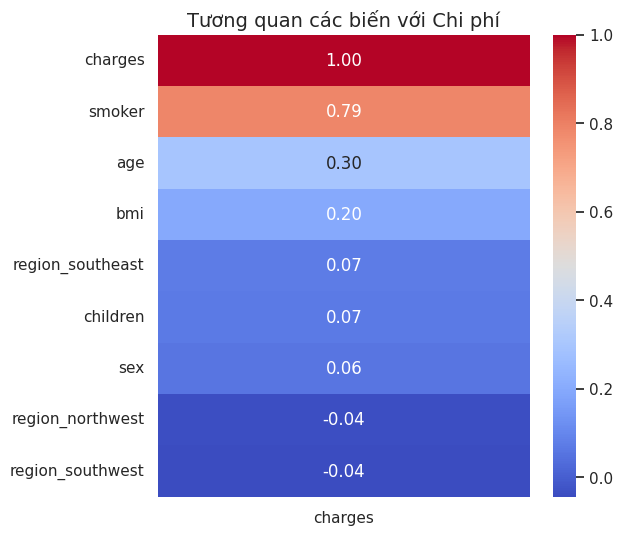

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 1, figsize=(6, 6), squeeze=False)

# Biểu đồ 1: Heatmap tương quan với Chi phí
corr = df_clean.corr()
sns.heatmap(corr[['charges']].sort_values(by='charges', ascending=False),
            annot=True, cmap='coolwarm', fmt=".2f", ax=axes[0, 0])
axes[0, 0].set_title('Tương quan các biến với Chi phí', fontsize=14)
plt.show()

-	***Quan sát số liệu:*** Biến smoker thể hiện số lượng áp đảo với hệ số tương quan tuyến tính dương cực cao r = 0.79. Biến ege đứng thứ 2 với r = 0.30 và bmi thứ 3 với r = 0.20. Các biến như sex, region, children có hệ số tương quan gần với mức 0.
-	***Diễn giải chuyên sâu – Deep Insight:*** Nhìn vào bản đồ nhiệt trên ta có thể thấy chi phí y tế không bị chi phối nhiều bởi các yếu tố bẩm sinh như giới tính hay môi trường địa lý, mà bị quyết định chủ yếu bởi sự lão hóa tự nhiên như tuổi tác và sự lựa chọn lối sống như hút thuốc. Đối với các công ty bảo hiểm, đây như một gợi ý với họ rằng họ không nên lãng phí nguồn lực để phân loại rủi ro theo vùng miền sinh sống hay giới tính mà nên dồn trọng tâm vào sàng lọc tuổi tác cũng như lối sống của khách hàng (ví dụ như tiền sử hút thuốc).


### **2.	Boxplot: Biến động chi phí giữ nhóm hút thuốc và nhóm không hút thuốc**

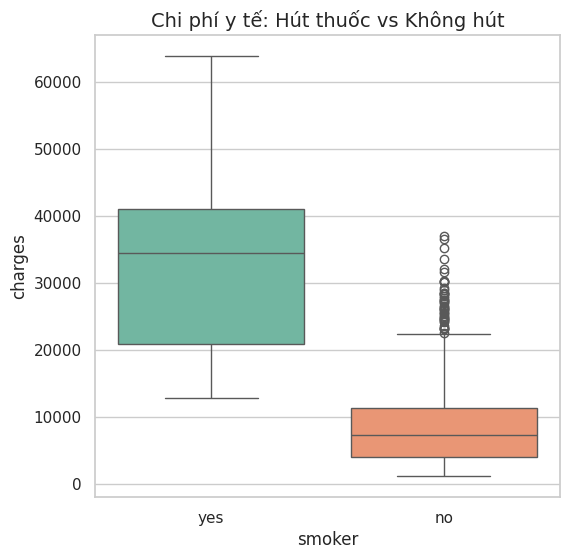

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 1, figsize=(6, 6), squeeze=False)

# Biểu đồ 2: Boxplot chi phí theo việc hút thuốc
sns.boxplot(x='smoker', y='charges', data=df, ax=axes[0, 0], palette='Set2')
axes[0, 0].set_title('Chi phí y tế: Hút thuốc vs Không hút', fontsize=14)
plt.show()

-	***Quan sát số liệu:*** Có thể thấy rằng khoảng cách tài chính giữa hai nhóm này là rất lớn. Nhóm không hút thuốc có mức chi phí trung vị chỉ khoảng ~7.000 USD, phần lớn biến động trong vùng an toàn (dưới 15.000 USD). Ngược lại, nhóm hút thuốc có chi phí trung vị lên tới ~35.000 USD cao gấp ~5 lần so với nhóm không hút thuốc. Đáng chú ý, hộp phân phối từ Q1 đến Q3 của nhóm hút thuốc rất rộng, trải từ 20.000USD đến hơn 40.000USD.
-	***Diễn giải chuyên sâu – Deep Insight:*** Việc hút thuốc không chỉ làm tăng chi phí nền, mà còn tạo ra sự bất ổn định trong quá trình bồi thường. Một khách hàng hút thuốc có thể tiêu tốn 20.000 USD, nhưng cũng có thể lên tới gần 50.000 USD bất cứ lúc nào do các biến chứng bệnh lý đột ngột như tim mạch, phổi. Đây là tệp khách hàng ảnh hưởng trực tiếp đến thanh khoản của các công ty bảo hiểm nếu không có mức phí dự phòng đủ dày.


### **3.	Scatter Plot: Tác động kép của chỉ số BMI và việc hút thuốc**

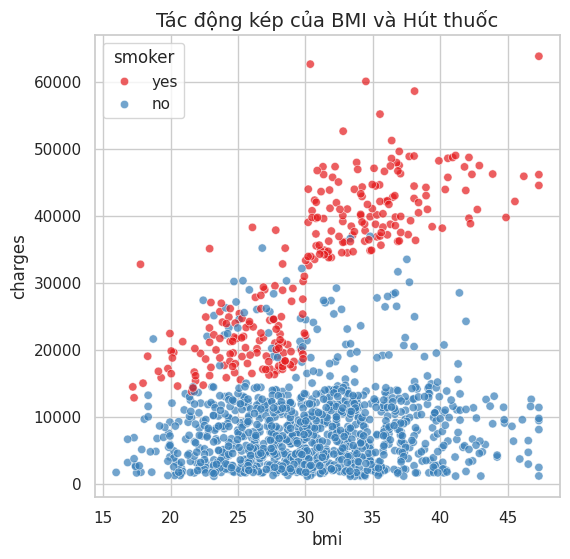

In [ ]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 1, figsize=(6, 6), squeeze=False)

# Biểu đồ 3: Scatter plot tác động kép của BMI & Hút thuốc
sns.scatterplot(x='bmi', y='charges', hue='smoker', data=df, ax=axes[0, 0], palette='Set1', alpha=0.7)
axes[0, 0].set_title('Tác động kép của BMI và Hút thuốc', fontsize=14)
plt.show()

-	***Quan sát số liệu:*** Đây là phát hiện khá thú vị cũng như là rất quan trọng trong bài toán này. Có thể nhìn thấy nhóm điểm màu xanh là nhóm không hút thuốc, ta thấy dù chỉ số BMI có tăng dần thì chi phí y tế vẫn đi ngang chủ yếu ở mức thấp không quá cao. Tuy nhiên, khi nhìn sang nhóm điểm màu đỏ chính là nhóm hút thuốc, một ranh giới khá là rõ ràng xuất hiện tại mốc BMI = 30, đây là ngưỡng béo phì. Khách hàng hút thuốc nhưng BMI < 30 chỉ tốn khoảng 15.000 - 30.000 USD. Nhưng khi khách hàng vừa hút thuốc và vừa có BMI > 30, chi phí lập tức vọt lên thành một cụm biệt lập ta có thể nhìn thấy ở đỉnh trên bên phải biểu đồ, chi phí khoảng 35.000 - 65.000 USD.
-	***Diễn giải chuyên sâu – Deep Insight:*** Những người béo phì với chỉ số BMI > 30 không tự làm chi phí tăng cao, tuy nhiên sự cộng hưởng giữa béo phì và hút thuốc đã tạo ra sự ảnh hưởng rất lớn tới sức khỏe. Nó sẽ gây ra những bệnh lý khác nhau từ đó dẫn đến chi phí càng tăng cao.


## ***IV. Giai đoạn 4: Kiểm định giả thuyết thống kê***

### **1. Giả thuyết 1: Tác động của nối sống hút thuốc vs không hút thuốc.**

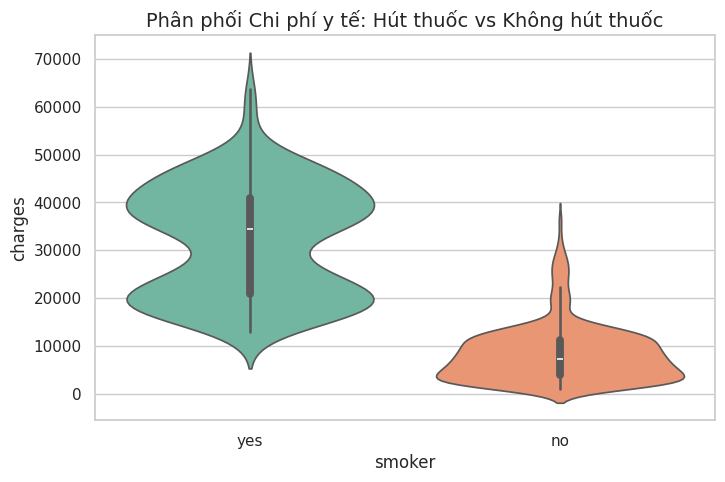

T-statistic: 32.7423 | P-value: 6.261720774727631e-103


In [ ]:
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Trực quan hóa bằng Violin Plot (cho thấy rõ sự phân bố và độ dày của dữ liệu hơn Boxplot)
plt.figure(figsize=(8, 5))
sns.violinplot(x='smoker', y='charges', data=df, palette='Set2')
plt.title('Phân phối Chi phí y tế: Hút thuốc vs Không hút thuốc', fontsize=14)
plt.show()

# 2. Kiểm định T-test
charges_smoker = df_clean[df_clean['smoker'] == 1]['charges']
charges_non_smoker = df_clean[df_clean['smoker'] == 0]['charges']

t_stat, p_val = stats.ttest_ind(charges_smoker, charges_non_smoker, equal_var=False)
print(f"T-statistic: {t_stat:.4f} | P-value: {p_val}")

**1.1.  Phát biểu:**
  * ***H0 (Giả thuyết không):*** Không có sự khác biệt về chi phí y tế trung bình giữa nhóm khách hàng hút thuốc và không hút thuốc.
  * ***H1 (Giả thuyết đối):*** Có sự khác biệt có ý nghĩa thống kê về chi phí y tế giữa hai nhóm này.
  * ***Phương pháp:*** Independent T-test (Kiểm định T-test cho 2 mẫu độc lập).

**1.2. Nhận xét phân tích**
  * ***Kết luận Giả thuyết 1:*** P-value xấp xỉ 0 (nhỏ hơn rất nhiều so với mức ý nghĩa 0.05), do đó chúng ta bác bỏ H0.
  * ***Business Insight:*** Biểu đồ Violin cho thấy nhóm không hút thuốc (phình to ở đáy) tập trung chủ yếu ở mức chi phí thấp (< 15.000 USD). Ngược lại, nhóm hút thuốc có phân phối kéo dài và tách biệt hẳn ở mức cao (30.000 - 50.000 USD). Kiểm định T-test khẳng định sự chênh lệch này là bản chất của dữ liệu chứ không phải do ngẫu nhiên. Việc hút thuốc là rủi ro định giá số 1 mà công ty bảo hiểm cần quan tâm.

### **2. Giả thuyết 2: Tác động của thể trạng (Chỉ số BMI vs Chi phí)**

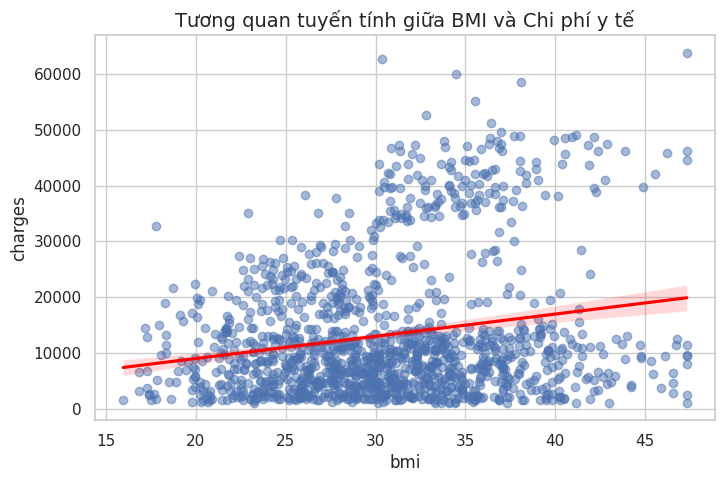

Hệ số tương quan (r): 0.1991 | P-value: 2.048826559375491e-13


In [ ]:
# 1. Trực quan hóa bằng Regplot (Scatter plot có kèm đường xu hướng)
plt.figure(figsize=(8, 5))
sns.regplot(x='bmi', y='charges', data=df, scatter_kws={'alpha':0.5}, line_kws={'color':'red'})
plt.title('Tương quan tuyến tính giữa BMI và Chi phí y tế', fontsize=14)
plt.show()

# 2. Kiểm định Pearson
corr_coef, p_val_bmi = stats.pearsonr(df_clean['bmi'], df_clean['charges'])
print(f"Hệ số tương quan (r): {corr_coef:.4f} | P-value: {p_val_bmi}")

**2.1. Phát biểu**
  * ***H0:*** Không có mối tương quan tuyến tính giữa chỉ số khối cơ thể (BMI) và Chi phí y tế.
  * ***H1:*** Có mối tương quan tuyến tính giữa hai biến này (BMI càng cao, chi phí càng lớn).
  * ***Phương pháp:*** Kiểm định Tương quan Pearson (Pearson Correlation).

**2.2. Nhận xét phân tích**

  * ***Kết luận Giả thuyết 2:*** P-value < 0.05, do đó chúng ta bác bỏ H0. Hệ số tương quan r ~ 0.2 (tương quan thuận).
  * ***Business Insight:*** Đường xu hướng (màu đỏ) hướng lên chứng tỏ chỉ số BMI có tác động làm tăng chi phí y tế. Tuy nhiên, mức độ tương quan tuyến tính chỉ ở mức yếu đến trung bình (do sự phân tán dữ liệu khá rộng). Điều này gợi ý rằng BMI có thể không tác động độc lập một cách mạnh mẽ, mà nó cần một "chất xúc tác" khác (như việc hút thuốc) để thực sự làm bùng nổ chi phí.

### **3. Giả thuyết 3: Tác động kép (Béo phì kết hợp Hút thuốc)**

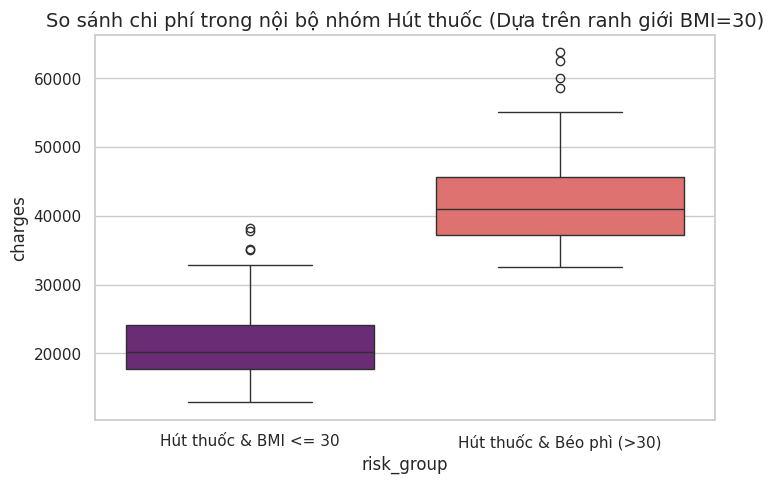

T-statistic: 30.9231 | P-value: 5.889813895207809e-91


In [ ]:
# Tạo cột phân nhóm mới để vẽ biểu đồ
df['risk_group'] = 'Khác'
df.loc[(df['smoker'] == 'yes') & (df['bmi'] <= 30), 'risk_group'] = 'Hút thuốc & BMI <= 30'
df.loc[(df['smoker'] == 'yes') & (df['bmi'] > 30), 'risk_group'] = 'Hút thuốc & Béo phì (>30)'

# 1. Trực quan hóa
plt.figure(figsize=(8, 5))
sns.boxplot(x='risk_group', y='charges', data=df[df['risk_group'] != 'Khác'], palette='magma')
plt.title('So sánh chi phí trong nội bộ nhóm Hút thuốc (Dựa trên ranh giới BMI=30)', fontsize=14)
plt.show()

# 2. Kiểm định T-test
smoker_obese = df_clean[(df_clean['smoker'] == 1) & (df_clean['bmi'] > 30)]['charges']
smoker_normal = df_clean[(df_clean['smoker'] == 1) & (df_clean['bmi'] <= 30)]['charges']

t_stat_k, p_val_k = stats.ttest_ind(smoker_obese, smoker_normal, equal_var=False)
print(f"T-statistic: {t_stat_k:.4f} | P-value: {p_val_k}")

**3.1. Phát biểu**

Từ gợi ý của biểu đồ Scatter ở EDA, ta chia nhóm hút thuốc thành 2 nhóm nhỏ để xem xét ngưỡng ranh giới BMI = 30.
  * ***H0:*** Trong nhóm khách hàng CÓ hút thuốc, chi phí y tế của người béo phì (BMI > 30) và người không béo phì (BMI <= 30) là như nhau.
  * ***H1:*** Chi phí của người hút thuốc bị béo phì cao hơn đáng kể so với người hút thuốc không béo phì.
  * ***Phương pháp:*** Independent T-test (Kiểm định T-test trên tập dữ liệu đã lọc).

**3.2. Nhận xét phân tích**

  * ***Kết luận Giả thuyết 3:*** P-value cực kỳ nhỏ, bác bỏ hoàn toàn H0. Trị số T-statistic rất cao chứng tỏ khoảng cách giữa 2 nhóm này là khổng lồ.
  * ***Business Insight:*** Đây là phát hiện quan trọng nhất của bài phân tích. Biểu đồ cho thấy ngưỡng BMI = 30 đóng vai trò như một "công tắc" rủi ro đối với người hút thuốc. Cùng là người hút thuốc, nhưng nếu giữ được thể trạng dưới mức béo phì, chi phí trung bình chỉ ở quanh 20.000 USD. Nhưng khi chạm ngưỡng béo phì, chi phí bật nhảy tạo thành một "vùng nguy hiểm" (khoảng 40.000 - 50.000 USD). Điều này là căn cứ vững chắc để thiết kế nhóm "Rủi ro nghiêm trọng" trong ma trận định giá bảo hiểm ở phần Khuyến nghị.

## ***V.	Giai đoạn 5: Đánh giá tác động và khuyến nghị***

### 1.	**Tóm tắt các phát hiện chuyên môn nổi bật**
-	Quy luật 80/20 trong bảo hiểm y tế tại tập dữ liệu này được định hình bởi hai yếu tố: Lối sống (Hút thuốc) và Thể trạng (BMI > 30).
-	Yếu tố độ tuổi thể hiện sự tăng trưởng chi phí một cách tuyến tính, chậm rãi và có thể dự báo trước dễ dàng. Trong khi đó yếu tố hút thuốc sẽ tạo ra sự tăng cao về chi phí một cách nhanh chóng.
### 2.	**Đề xuất giải pháp mang tính ứng dụng thực tế**
-	Tái cấu trúc Ma trận Định giá: Bộ phận Actuary cần phân tầng khách hàng làm 3 nhóm:
  * *Nhóm rủi ro thấp:* Không hút thuốc và không phân biệt BMI => Áp dụng mức phí bảo hiểm cơ bản cạnh tranh nhất để thu hút thị phần.
  * *Nhóm rủi ro trung bình:* Hút thuốc, nhưng BMI < 30 => Tăng hệ số rủi ro.
  * *Nhóm rủi ro nghiêm trọng:* Hút thuốc và Béo phì (BMI > 30) => Cần áp dụng mức phí cao nhất hoặc yêu cầu đồng chi trả (Co-pay) cao hơn cho các bệnh lý liên quan đến tim mạch/hô hấp.
-	Chủ động can thiệt và chăm sóc khách hàng: Thay vì chỉ ngồi chờ khách hàng ốm và bồi thường, công ty bảo hiểm nên chủ động chi tiền trước. Hãy tài trợ các khóa học cai thuốc lá hoặc các khóa học giảm cân cho tệp khách hàng nguy cơ cao. Khoản hoàn phí này rẻ hơn rất nhiều so với việc phải chi trả 50.000 USD tiền viện phí.
### 3.	**Giới hạn của tệp dữ liệu và hướng mở rộng trong tương lai**
-	***Hạn chế:*** Tập dữ liệu tương đối nhỏ chỉ có 1337 dòng và chỉ là dữ liệu lát cắt ngang tại một thời điểm. Nó hoàn toàn thiếu vắng các đặc trưng cốt lõi như: Tiền sử gia đình (di truyền), loại hình can thiệp y khoa như phẫu thuật hay dùng thuốc, hay tính chất nghề nghiệp của khách hàng như ngồi văn phòng hay lao động độc hại.
-	***Hướng mở rộng:*** Để xây dựng một hệ thống định giá thực sự tối ưu, nhóm phân tích cần thu thập thêm dữ liệu chuỗi thời gian để theo dõi lịch sử khám chữa bệnh của một người qua nhiều năm. Kết hợp thêm các mô hình học máy thay vì chỉ dùng hồi quy tuyến tính để mô hình có thể tự động học được các ranh giới phi tuyến tính như ranh giới BMI = 30 đã phát hiện ở trên.

### 4. **Dự báo chi phí y tế bằng mô hình học máy**

4. XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH HỌC MÁY
- Linear Regression -> Độ chính xác (R2): 0.8071 | Sai số tuyệt đối trung bình (MAE): 4181.90 USD
- Random Forest     -> Độ chính xác (R2): 0.8797 | Sai số tuyệt đối trung bình (MAE): 2636.78 USD


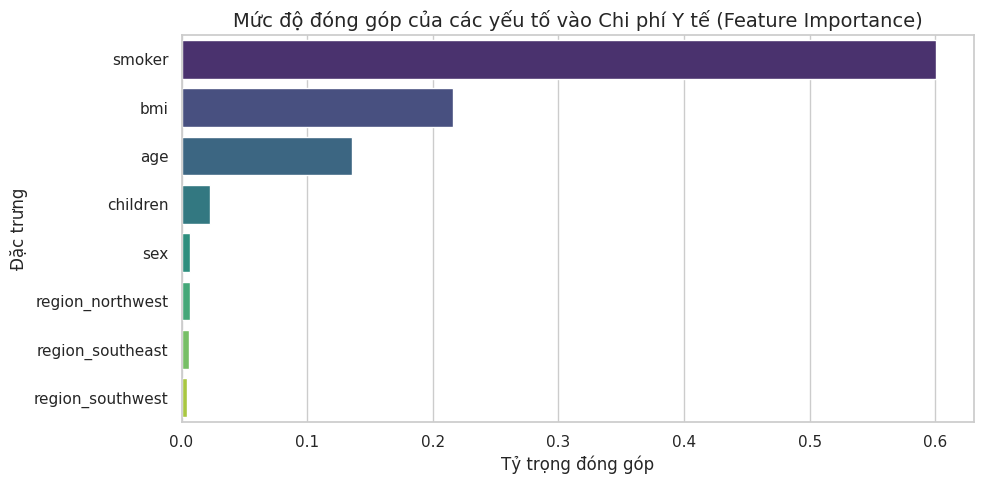

In [ ]:
# --- GIAI ĐOẠN 4: ỨNG DỤNG MÔ HÌNH HỌC MÁY (MACHINE LEARNING) ---
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import numpy as np

print("4. XÂY DỰNG VÀ ĐÁNH GIÁ MÔ HÌNH HỌC MÁY")

# 1. Tách biến độc lập (X) và biến phụ thuộc/Mục tiêu (y)
X = df_clean.drop('charges', axis=1)
y = df_clean['charges']

# Tách tập dữ liệu thành Tập huấn luyện (Train) và Tập kiểm tra (Test) theo tỷ lệ 80:20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Huấn luyện mô hình Hồi quy tuyến tính (Linear Regression)
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_preds = lr_model.predict(X_test)

lr_r2 = r2_score(y_test, lr_preds)
lr_mae = mean_absolute_error(y_test, lr_preds)
print(f"- Linear Regression -> Độ chính xác (R2): {lr_r2:.4f} | Sai số tuyệt đối trung bình (MAE): {lr_mae:.2f} USD")

# 3. Huấn luyện mô hình Rừng ngẫu nhiên (Random Forest Regressor)
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)
rf_preds = rf_model.predict(X_test)

rf_r2 = r2_score(y_test, rf_preds)
rf_mae = mean_absolute_error(y_test, rf_preds)
print(f"- Random Forest     -> Độ chính xác (R2): {rf_r2:.4f} | Sai số tuyệt đối trung bình (MAE): {rf_mae:.2f} USD")

# 4. Trực quan hóa Tầm quan trọng của các đặc trưng (Feature Importance) từ Random Forest
feature_importances = pd.DataFrame({'Feature': X.columns, 'Importance': rf_model.feature_importances_})
feature_importances = feature_importances.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feature_importances, palette='viridis')
plt.title('Mức độ đóng góp của các yếu tố vào Chi phí Y tế (Feature Importance)', fontsize=14)
plt.xlabel('Tỷ trọng đóng góp')
plt.ylabel('Đặc trưng')
plt.tight_layout()
plt.show()

Để dự báo chi phí y tế cho một khách hàng mới trong tương lai, nhóm tiến hành xây dựng các mô hình học máy. Dữ liệu được chia theo tỷ lệ 80/20 (80% để huấn luyện mô hình, 20% để kiểm tra độ chính xác).
1. **Giải trình lựa chọn và Đánh giá mô hình (Model Evaluation)**

  - ***Nhóm thử nghiệm hai mô hình:*** Hồi quy tuyến tính (Linear Regression) đại diện cho các thuật toán tuyến tính cơ bản, và Rừng ngẫu nhiên (Random Forest Regressor) đại diện cho các thuật toán học máy tập hợp (Ensemble Learning) có khả năng xử lý phi tuyến tính. Kết quả trên tập Kiểm tra (Test set) như sau:
    * **Linear Regression:** Độ chính xác ($R^2$) đạt 0.8071, Sai số tuyệt đối trung bình (MAE) là 4181.90 USD.
    * **Random Forest:** Độ chính xác ($R^2$) đạt 0.8797, Sai số tuyệt đối trung bình (MAE) giảm đáng kể xuống còn 2636.78 USD.
  - ***Deep Insight:*** Mô hình Random Forest vượt trội hơn hẳn Linear Regression (độ chính xác xấp xỉ 88% so với 80%). Điều này chứng minh nhận định ở Giai đoạn 3 (EDA) của nhóm là hoàn toàn chính xác: Mối quan hệ giữa chi phí y tế và các biến số không hoàn toàn là đường thẳng tuyến tính. Cụ thể, mô hình Random Forest với cấu trúc cây quyết định đã học được "hiệu ứng cộng hưởng" (béo phì BMI > 30 kết hợp với việc hút thuốc sẽ làm chi phí tăng vọt), điều mà mô hình Hồi quy tuyến tính truyền thống không thể nắm bắt được.
2. **Tầm quan trọng của các đặc trưng (Feature Importance)**

- Dựa trên thuật toán của Random Forest, nhóm đã trích xuất được tỷ trọng đóng góp của từng biến số vào sự biến thiên của chi phí y tế:
  * **Phân tích số liệu:** Yếu tố hút thuốc (smoker) chiếm trọng số áp đảo lên tới 60.1% trong việc quyết định chi phí. Tiếp theo là chỉ số khối cơ thể béo phì (bmi) đóng góp 21.6%, và độ tuổi lão hóa (age) đóng góp 13.5%. Tổng cộng 3 biến số thuộc về lối sống và thể chất này giải thích tới 95.2% rủi ro tài chính của một hợp đồng bảo hiểm. Các yếu tố vùng miền và giới tính đóng góp chưa tới 1% mỗi biến.
  * **Kết luận:** Máy học một lần nữa củng cố chắc chắn các giả thuyết phân tích dữ liệu thủ công của nhóm. Hệ thống định phí bảo hiểm chỉ cần thu thập 3 thông tin cốt lõi (Có hút thuốc không? Chiều cao/cân nặng bao nhiêu? Bao nhiêu tuổi?) là đã đủ cơ sở để đưa ra mức phí bồi thường dự kiến với độ tin cậy lên tới gần 88%.